# 배당 계산기 + 몬테카를로 (Colab)

**하는 일**: 데이터수집팀이 채운 `배당계산기_데이터_수집양식_v2.xlsx`(⑩ 등기부 권리, ⑩-2 임차인)와
보정된 낙찰가 예측(`calib_out/auction_predictions.csv`)을 읽어서, 사건마다
**신보 회수액 분포(중앙값·범위·0원 확률)**와 **실제 매각가 기준 배당표**를 계산합니다.

- 데이터가 일부만 들어와도 돌아갑니다. ⑩에 한 줄이라도 있는 사건만 계산하고, 나머지는 "대기"로 표시해요.
- 새 데이터가 들어오면 **엑셀만 드라이브에 덮어쓰고 [런타임 → 모두 실행]** 하면 됩니다.
- 결과: `data/dividend_out/` 에 결과표·배당표·대시보드용 JSON 저장.

**순서**: 준비 → 0 설정(가정값) → 1 배당 엔진 → 2 손계산 테스트 → 3 데이터 읽기 → 4 사건별 권리 정리 → 5 몬테카를로 → 6 저장

## 준비: 드라이브 연결

In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

import os, glob, json, re, unicodedata
from pathlib import Path
import numpy as np
import pandas as pd

def nfc(s): return unicodedata.normalize("NFC", str(s))

def find_project(name="신보프로젝트"):
    roots = [Path("/content/drive/MyDrive"), Path("/content/drive/.shortcut-targets-by-id")]
    for r in roots:
        if not r.exists(): continue
        for p in [r] + [q for q in r.iterdir() if q.is_dir()]:
            for c in ([p] + [q for q in p.iterdir() if q.is_dir()] if p.is_dir() else []):
                if nfc(c.name) == nfc(name): return c
    raise FileNotFoundError(f"드라이브에서 '{name}' 폴더를 못 찾았어요.")

def sub(base, *parts):
    p = base
    for part in parts:
        hit = [q for q in p.iterdir() if nfc(q.name) == nfc(part)] if p.exists() else []
        p = hit[0] if hit else p / part
    return p

BASE = find_project()
DATA = sub(BASE, "data")
OUT = DATA / "dividend_out"; OUT.mkdir(exist_ok=True)
print("프로젝트:", BASE)

Mounted at /content/drive
프로젝트: /content/drive/MyDrive/신보프로젝트


## 0단계: 설정 (가정값) — 팀이 정하면 여기만 바꾸세요

대시보드에서도 같은 값을 조정할 수 있게 할 예정이고, 여기 값은 **기본값**이에요.

In [2]:
# --- 신보 설정 ---
SINBO_MODE   = "general"   # "general" = 맨 뒤 일반채권자(가압류, 안분) / "attach" = 가압류 날짜 지정 / "mortgage" = 근저당 날짜 지정
SINBO_DATE   = None        # attach·mortgage일 때 신보 등기 날짜 (예: "2021-03-01"). general이면 None
SINBO_AMOUNT_RATE = 0.30   # 신보 채권액 = 감정가 × 이 비율  (팀 확정 전 임시값)
SINBO_AMOUNT_FIXED = None  # 금액으로 정하려면 숫자(원). 정하면 위 비율 무시
USE_ACTUAL_SINBO = True    # 등기부에 신보가 실제로 나오면 그 값을 우선 사용

# --- 모르는 값 (역추정) ---
COST_RATE       = 0.01     # 집행비용 = 감정가 × 1%
MORTGAGE_RATIO  = 1.2      # 근저당 실제 잔액 = 채권최고액 ÷ 1.2  (1.0이면 최고액 그대로)
TAX_SCENARIOS   = [0, 30_000_000, 60_000_000, 120_000_000]   # 세금 압류는 있는데 금액이 없을 때, 같은 확률로 추출
INCLUDE_AUCTION_CLAIM = False   # 경매개시결정 행의 청구금액을 일반채권으로 넣을지 (근저당과 중복될 수 있어 기본 False)

# --- 몬테카를로 ---
N_SIM = 10_000
SEED  = 2026

def sinbo_amount(apsl):
    return float(SINBO_AMOUNT_FIXED) if SINBO_AMOUNT_FIXED else float(apsl) * SINBO_AMOUNT_RATE

## 1단계: 배당 엔진

**입력**: 낙찰가(여러 개를 한 번에, 1만 개 배열) + 순위 그룹 목록
**규칙** (11/14 최종 정리 기준, 단순화)
1. 집행비용 (감정가 × 1%)
2. 최우선: 소액임차인 일정액(매각가 × 한도비율까지) + 근로복지공단(임금) — 같은 순위, 모자라면 비율로
3. 날짜 경쟁: 근저당·전세권·임차권등기·확정일자 임차인 잔액·세금 압류·공단 압류 → **날짜순**, 같은 날이면 비율로
   - 가압류가 어떤 근저당보다 먼저면 → 그 뒤 첫 근저당과 **같은 그룹**에서 비율로 (안분배당 예외, 흡수배당은 미반영)
4. 일반채권: 나머지 가압류 + 신보(일반채권자) → 비율로

In [3]:
def waterfall(prices, groups):
    """prices: (n,) 배열. groups: [{"name":..., "claims":[{"id","name","amount", "cap_rate"(선택)}]}...]
    반환: {claim_id: (n,) 배당액 배열}, 남은 돈"""
    prices = np.asarray(prices, dtype=float)
    remain = prices.copy()
    paid = {}
    for g in groups:
        want = []
        for c in g["claims"]:
            w = np.full_like(prices, float(c["amount"]))
            want.append(w)
        if not want: continue
        W = np.vstack(want)                              # (k, n)
        # 그룹 상한 (소액임차인: 매각가 × 한도비율, 유형별)
        if g.get("caps"):
            for cap_rate, idx in g["caps"]:              # idx: 이 상한이 적용되는 claim 위치들
                tot = W[idx].sum(axis=0)
                lim = prices * cap_rate
                scale = np.where(tot > lim, lim / np.maximum(tot, 1e-9), 1.0)
                W[idx] = W[idx] * scale
        total = W.sum(axis=0)
        give = np.minimum(total, np.maximum(remain, 0))
        share = np.where(total > 0, W / np.maximum(total, 1e-9), 0) * give
        for c, s in zip(g["claims"], share):
            paid[c["id"]] = paid.get(c["id"], 0) + s
        remain = remain - give
    return paid, remain

def sample_ratio(p10, p50, p90, n, rng):
    """P10/P50/P90 사이 선형 보간 + 꼬리 연장 (하한 1%)"""
    p10, p50, p90 = np.sort([p10, p50, p90])
    lo = p10 - 0.5 * (p50 - p10); hi = p90 + 0.5 * (p90 - p50)
    u = rng.random(n)
    r = np.interp(u, [0.0, 0.1, 0.5, 0.9, 1.0], [lo, p10, p50, p90, hi])
    return np.maximum(r, 0.01)

## 2단계: 손계산 테스트 — 엔진이 규칙대로 도는지 확인

손으로 계산한 정답과 코드 결과가 같아야 해요. 하나라도 틀리면 여기서 멈춥니다.

In [4]:
def G(name, claims, caps=None):
    return {"name": name, "claims": claims, **({"caps": caps} if caps else {})}

def C(cid, amount): return {"id": cid, "name": cid, "amount": amount}

def check(label, got, want, tol=1):
    ok = abs(float(got) - want) <= tol
    print(("✅" if ok else "❌"), f"{label}: 코드 {float(got):,.0f} / 정답 {want:,.0f}")
    assert ok, label

# T1: 낙찰가 6억, 집행비용 1,000만, 선순위 5.4억, 신보 3억 + 다른 가압류 2억 → 남은 5천만 × 3/5
groups = [G("집행비용", [C("비용", 10_000_000)]), G("근저당", [C("은행", 540_000_000)]),
          G("일반", [C("신보", 300_000_000), C("캐피탈", 200_000_000)])]
p, _ = waterfall([600_000_000], groups); check("T1 신보", p["신보"][0], 30_000_000)
# T2: 낙찰가 5억이면 신보 0원
p, _ = waterfall([500_000_000], groups); check("T2 신보", p["신보"][0], 0)
# T3: 같은 날 근저당 2개는 비율로 — 남은 3억을 2억:4억 → 1억 / 2억
p, _ = waterfall([300_000_000], [G("같은날", [C("A", 200_000_000), C("B", 400_000_000)])])
check("T3 A", p["A"][0], 100_000_000); check("T3 B", p["B"][0], 200_000_000)
# T4: 소액임차인 상한 — 매각가 1억 × 1/2 = 5천만, 임차인 2명 일정액 2,800만 + 2,800만 = 5,600만 → 비율로 2,500만씩
p, _ = waterfall([100_000_000], [G("최우선", [C("임1", 28_000_000), C("임2", 28_000_000)], caps=[(0.5, [0, 1])])])
check("T4 임차인1", p["임1"][0], 25_000_000)
# T5: 안분 예외 — 신보 가압류(2019)가 근저당(2020)보다 먼저 → 같은 그룹, 4억을 3억:3억 → 2억씩
p, _ = waterfall([400_000_000], [G("2020 그룹", [C("신보", 300_000_000), C("은행", 300_000_000)])])
check("T5 신보", p["신보"][0], 200_000_000)
print("손계산 테스트 모두 통과")

✅ T1 신보: 코드 30,000,000 / 정답 30,000,000
✅ T2 신보: 코드 0 / 정답 0
✅ T3 A: 코드 100,000,000 / 정답 100,000,000
✅ T3 B: 코드 200,000,000 / 정답 200,000,000
✅ T4 임차인1: 코드 25,000,000 / 정답 25,000,000
✅ T5 신보: 코드 200,000,000 / 정답 200,000,000
손계산 테스트 모두 통과


## 3단계: 데이터 읽기

- 수집양식 엑셀: `data/` 안에서 이름에 **수집양식**이 들어간 가장 최근 파일을 자동으로 찾아요.
- 낙찰가 예측: `data/calib_out/auction_predictions.csv`

In [5]:
def latest(pattern_dir, key):
    fs = [p for p in pattern_dir.iterdir() if key in nfc(p.name) and p.suffix.lower() == ".xlsx" and not p.name.startswith("~$")]
    if not fs: raise FileNotFoundError(f"data 폴더에 '{key}' 엑셀이 없어요.")
    return max(fs, key=lambda p: p.stat().st_mtime)

XLSX = latest(DATA, "수집양식")
print("수집양식:", XLSX.name)

def rd(sheet, header):
    return pd.read_excel(XLSX, sheet_name=sheet, header=header)

target = rd("⓪ 대상 사건", 4)
target = target[target["사건번호"].notna() & pd.to_numeric(target["순서"], errors="coerce").notna()]   # 순서가 숫자인 행만 (1.0도 허용)
reg    = rd("⑩ 등기부 권리", 4).dropna(subset=["사건번호"])
ten    = rd("⑩-2 임차인", 4).dropna(subset=["사건번호"])
small_tbl = rd("⑨ 소액임차 기준표", 4).dropna(subset=["시작일"])
small_tbl = small_tbl[small_tbl["구분"].isin(["주택", "상가"])]
region_tbl = rd("⑨ 지역 구분", 3).dropna(subset=["시·군·구"])

pred = pd.read_csv(sub(DATA, "calib_out", "auction_predictions.csv"))
pred["key"] = pred["사건"].str.split(" ", n=1).str[1]          # "2025타경7702-1"

def todate(v):
    if pd.isna(v) or str(v).strip() == "": return pd.NaT
    s = str(v).strip().replace(".", "-")
    return pd.to_datetime(s, errors="coerce")

def tonum(v):
    if pd.isna(v): return np.nan
    s = re.sub(r"[^\d.]", "", str(v))
    return float(s) if s else np.nan

def key_of(caseno, item): return f"{str(caseno).strip()}-{int(float(item)) if pd.notna(item) else 1}"

for df in (reg, ten): df["key"] = [key_of(a, b) for a, b in zip(df["사건번호"], df["물건번호"])]
target["key"] = [key_of(a, b) for a, b in zip(target["사건번호"], target["물건번호"])]
reg["접수일"] = reg["접수일"].map(todate); reg["금액"] = reg["금액(원)"].map(tonum)
reg["유효"] = reg["경매 당시 유효"].astype(str).str.strip().str.upper().ne("N")   # 비워두면 유효로 봄
for c in ["전입일 (상가는 사업자등록일)", "확정일자", "배당요구일"]: ten[c] = ten[c].map(todate)
ten["보증금"] = ten["보증금(원)"].map(tonum).fillna(0); ten["월세"] = ten["월세(원)"].map(tonum).fillna(0)

have = set(reg["key"])
print(f"대상 {len(target)}건 중 등기부 입력된 사건 {len(target[target.key.isin(have)])}건, 임차인 행 {len(ten)}개")

수집양식: 배당계산기_데이터_수집양식_v2.xlsx
대상 50건 중 등기부 입력된 사건 50건, 임차인 행 53개


## 4단계: 사건별로 권리를 순위 그룹으로 정리

In [6]:
def region_of(addr):
    a = nfc(addr)
    m = re.match(r"(대구광역시|경상북도)\s+(\S+?(시|군|구))", a)
    if not m: return "그 밖의 지역"
    name = ("대구 " if m.group(1).startswith("대구") else "경북 ") + m.group(2)
    hit = region_tbl[region_tbl["시·군·구"].map(nfc) == name]
    return hit["기준 지역"].iloc[0] if len(hit) else "그 밖의 지역"

def small_rule(kind, region, base_date):
    t = small_tbl[(small_tbl["구분"] == kind) & (small_tbl["지역"] == region)]
    d = base_date if pd.notna(base_date) else pd.Timestamp.today()
    def ts(v): return pd.Timestamp.max if str(v).startswith("9999") else pd.Timestamp(v)   # 9999-12-31 = 현재 적용 중
    t = t[t["시작일"].map(ts).le(d) & t["종료일"].map(ts).ge(d)]
    return None if t.empty else t.iloc[0]

def build_case(row, verbose=False):
    """⓪ 한 행 → (groups 생성 함수, 정보). 세금 시나리오가 필요하면 tax_needed=True"""
    k = row["key"]; apsl = float(row["감정가(원)"])
    base_date = todate(row["최선순위 설정일"])
    region = region_of(row["소재지"])
    R = reg[(reg.key == k) & reg.유효].copy()
    T = ten[ten.key == k].copy()
    notes = []

    auction_date = R.loc[R["등기목적"] == "경매개시결정", "접수일"].min()
    secured, general, prio, prio_caps = [], [], [], []
    tax_rows_without_amount, tax_dates = 0, []
    sinbo_actual = R[R["권리자 유형"] == "신보"]

    sinbo_used = {}                                   # 실제로 배당에 들어간 신보 행 → 금액
    for i, r in R.iterrows():
        typ, who, amt, d = r["등기목적"], r["권리자 유형"], r["금액"], r["접수일"]
        cid = f"r{i}"; nm = f"{who or ''} {typ}".strip()
        if who == "신보" and not USE_ACTUAL_SINBO: continue
        if who == "신보" and typ in ("근저당권설정", "전세권설정", "가압류") and pd.notna(amt): sinbo_used[cid] = amt
        if who == "신보" and typ not in ("근저당권설정", "전세권설정", "가압류", "경매개시결정"):
            notes.append(f"신보 '{typ}' 행은 배당에 안 들어감 → 근저당 이전이면 근저당권설정으로 입력")
        if who == "근로복지공단":
            if pd.notna(amt): prio.append({"id": cid, "name": "근로복지공단(임금)", "amount": amt})
            else: notes.append("근로복지공단 금액 없음 → 0 처리")
            continue
        if typ in ("근저당권설정", "전세권설정", "임차권등기"):
            if pd.isna(amt): notes.append(f"{nm} 금액 없음 → 제외"); continue
            a = amt / MORTGAGE_RATIO if typ == "근저당권설정" and who != "신보" else amt
            secured.append({"id": cid, "name": nm, "amount": a, "date": d, "kind": "담보"})
        elif typ == "압류":
            if who in ("세무서", "지자체"):
                tax_dates.append(d)
                if pd.notna(amt): secured.append({"id": cid, "name": nm, "amount": amt, "date": d, "kind": "세금"})
                else: tax_rows_without_amount += 1
            elif pd.notna(amt):
                secured.append({"id": cid, "name": nm, "amount": amt, "date": d, "kind": "공과금"})
            else: notes.append(f"{nm} 금액 없음 → 0 처리")
        elif typ == "가압류":
            if pd.isna(amt): notes.append(f"{nm} 금액 없음 → 제외"); continue
            general.append({"id": cid, "name": nm, "amount": amt, "date": d, "kind": "가압류"})
        elif typ == "경매개시결정" and INCLUDE_AUCTION_CLAIM and pd.notna(amt):
            general.append({"id": cid, "name": nm, "amount": amt, "date": d, "kind": "가압류"})

    # 임차인
    for i, t in T.iterrows():
        if str(t["배당요구 여부"]).strip().upper() != "Y":
            notes.append(f"임차인{t['임차인 번호']} 배당요구 없음 → 제외"); continue
        kind = "상가" if str(t["구분"]).strip() == "상가" else "주택"
        dep, rent = t["보증금"], t["월세"]
        judge = dep + rent * 100 if kind == "상가" else dep                  # 상가는 환산보증금
        moved = t["전입일 (상가는 사업자등록일)"]
        rule = small_rule(kind, region, base_date)
        first = 0.0
        ok_time = pd.isna(auction_date) or (pd.notna(moved) and moved < auction_date)
        if rule is not None and judge <= rule["소액 보증금 상한"] and ok_time:
            first = min(dep, float(rule["최우선변제액"]))
            prio.append({"id": f"t{i}a", "name": f"임차인{t['임차인 번호']} 최우선", "amount": first, "cap": float(rule["한도 비율"])})
        rest = dep - first
        conf = t["확정일자"]
        if rest > 0 and pd.notna(conf) and pd.notna(moved):
            d = max(moved + pd.Timedelta(days=1), conf)
            secured.append({"id": f"t{i}b", "name": f"임차인{t['임차인 번호']} 확정일자", "amount": rest, "date": d, "kind": "임차인"})

    # 신보 (가상) 추가
    B = sinbo_amount(apsl)
    if not (USE_ACTUAL_SINBO and sinbo_used):
        sd = todate(SINBO_DATE)
        if SINBO_MODE == "mortgage":
            secured.append({"id": "SINBO", "name": "신보(가정·근저당)", "amount": B, "date": sd, "kind": "담보"})
        elif SINBO_MODE == "attach":
            general.append({"id": "SINBO", "name": "신보(가정·가압류)", "amount": B, "date": sd, "kind": "가압류"})
        else:
            general.append({"id": "SINBO", "name": "신보(가정·일반채권)", "amount": B, "date": pd.NaT, "kind": "가압류"})
        sinbo_ids = ["SINBO"]
    else:
        B = float(sum(sinbo_used.values()))
        sinbo_ids = list(sinbo_used)
        notes.append("등기부의 실제 신보 채권 사용")

    # 안분 예외: 가압류가 근저당보다 먼저면 그 뒤 첫 근저당의 날짜로 올림
    mort_dates = sorted([c["date"] for c in secured if c["kind"] == "담보" and pd.notna(c["date"])])
    still_general = []
    for c in general:
        later = [m for m in mort_dates if pd.notna(c["date"]) and c["date"] < m]
        if later: secured.append({**c, "date": later[0], "kind": "가압류(안분)"})
        else: still_general.append(c)
    general = still_general

    tax_needed = tax_rows_without_amount > 0
    tax_date = min([d for d in tax_dates if pd.notna(d)], default=pd.NaT)

    def make_groups(tax_amount=0.0):
        g = [G("집행비용", [C("COST", apsl * COST_RATE)])]
        if prio:
            caps = {}
            for j, c in enumerate(prio):
                if "cap" in c: caps.setdefault(c["cap"], []).append(j)
            g.append(G("최우선", [{k2: v for k2, v in c.items() if k2 != "cap"} for c in prio], caps=list(caps.items())))
        sec = list(secured)
        if tax_amount > 0:
            sec.append({"id": "TAX", "name": "체납세금(추정)", "amount": tax_amount, "date": tax_date, "kind": "세금"})
        sec = sorted(sec, key=lambda c: (pd.Timestamp.max if pd.isna(c["date"]) else c["date"]))
        for d, grp in pd.DataFrame(sec).groupby(pd.DataFrame(sec)["date"].fillna(pd.Timestamp.max), sort=True) if sec else []:
            g.append(G(f"날짜 {pd.Timestamp(d).date() if d != pd.Timestamp.max else '미상'}",
                       [{"id": r.id, "name": r.name, "amount": r.amount} for r in grp.itertuples()]))
        if general:
            g.append(G("일반채권", [{"id": c["id"], "name": c["name"], "amount": c["amount"]} for c in general]))
        return g

    info = dict(sinbo_ids=sinbo_ids, key=k, 감정가=apsl, 지역=region, 최선순위=base_date, 신보채권액=B,
                세금시나리오=tax_needed, 권리수=len(R), 임차인수=len(T), 메모=" / ".join(dict.fromkeys(notes)))
    return make_groups, info

## 5단계: 몬테카를로 + 실제 매각가 배당표

In [7]:
rng = np.random.default_rng(SEED)
rows, tables, dash = [], [], []
for _, row in target.iterrows():
    k = row["key"]
    if k not in have:
        rows.append(dict(key=k, 상태="대기 (등기부 미입력)")); continue
    pr = pred[pred.key == k]
    if pr.empty:
        rows.append(dict(key=k, 상태="예측값 없음")); continue
    pr = pr.iloc[0]
    make_groups, info = build_case(row)
    apsl = info["감정가"]

    ratios = sample_ratio(pr.p10, pr.p50, pr.p90, N_SIM, rng)
    prices = apsl * ratios
    taxes = rng.choice(TAX_SCENARIOS, N_SIM) if info["세금시나리오"] else np.zeros(N_SIM)
    S = np.zeros(N_SIM)
    for tx in np.unique(taxes):                       # 세금 시나리오별로 묶어서 계산
        m = taxes == tx
        paid, _ = waterfall(prices[m], make_groups(tx))
        S[m] = sum(paid.get(sid, 0) for sid in info["sinbo_ids"])
    B = info["신보채권액"]

    # 실제 매각가 기준 배당표 (세금 시나리오 중간값 사용)
    actual = float(row["매각가(원)"])
    tx_mid = float(np.median(TAX_SCENARIOS)) if info["세금시나리오"] else 0.0
    paid_a, rem_a = waterfall([actual], make_groups(tx_mid))
    for g in make_groups(tx_mid):
        for c in g["claims"]:
            tables.append(dict(key=k, 순위그룹=g["name"], 권리=c["name"], 청구액=round(c["amount"]),
                               배당액=round(float(paid_a.get(c["id"], [0])[0]))))
    tables.append(dict(key=k, 순위그룹="잉여", 권리="소유자 반환", 청구액=None, 배당액=round(float(rem_a[0]))))

    rows.append(dict(**{kk: vv for kk, vv in info.items() if kk != "sinbo_ids"}, 상태="계산 완료", 매각가=actual, p10=pr.p10, p50=pr.p50, p90=pr.p90,
                     회수_중앙값=np.median(S), 회수_평균=S.mean(), 회수_P10=np.percentile(S, 10), 회수_P90=np.percentile(S, 90),
                     영원확률=(S <= 0.5).mean(), 회수율_중앙=np.median(S) / B if B else np.nan,
                     실제가_신보배당=float(sum(paid_a.get(sid, [0])[0] for sid in info["sinbo_ids"]))))
    dash.append(dict(key=k, 법원=row["법원"], 사건번호=row["사건번호"], 물건번호=int(row["물건번호"]), 용도=row["용도"],
                     소재지=row["소재지"], 감정가=apsl, 매각가=actual, p10=pr.p10, p50=pr.p50, p90=pr.p90,
                     지역=info["지역"], 최선순위=str(info["최선순위"].date()) if pd.notna(info["최선순위"]) else None,
                     세금시나리오=bool(info["세금시나리오"]),
                     groups=[{"name": g["name"], "claims": [{"name": c["name"], "amount": round(c["amount"])} for c in g["claims"] if c["id"] != "SINBO"]}
                             for g in make_groups(0) if g["name"] != "집행비용"]))

res = pd.DataFrame(rows, columns=None if rows else ["key", "상태"])
if res.empty: raise ValueError("⓪ 대상 사건에서 사건을 하나도 못 읽었어요. 시트 이름·머리글(5행) 확인")
done = res[res["상태"] == "계산 완료"]
print(f"계산 완료 {len(done)}건 / 대기 {int((res['상태'] != '계산 완료').sum())}건")
pd.options.display.float_format = "{:,.0f}".format
if len(done):
    show = done[["key", "감정가", "신보채권액", "회수_중앙값", "회수_P10", "회수_P90", "영원확률", "실제가_신보배당", "메모"]].copy()
    show["영원확률"] = (show["영원확률"] * 100).round(1).astype(str) + "%"
    display(show)

계산 완료 49건 / 대기 1건


,key,감정가,신보채권액,회수_중앙값,회수_P10,회수_P90,영원확률,실제가_신보배당,메모
0,2025타경8972-1,"164,000,000","49,200,000",0,0,0,100.0%,0,
1,2025타경844-1,"2,020,000,000","606,000,000",0,0,0,100.0%,0,임차인1 배당요구 없음 → 제외 / 임차인2 배당요구 없음 → 제외
2,2025타경951-7,"276,000,000","82,800,000",0,0,0,100.0%,0,
3,2025타경8809-1,"3,087,799,400","926,339,820",0,0,0,100.0%,0,건강보험공단 압류 금액 없음 → 0 처리 / 임차인1 배당요구 없음 → 제외 / 임...
4,2025타경423-1,"79,000,000","23,700,000",0,0,0,100.0%,0,
5,2025타경31962-1,"1,207,452,000","362,235,600",0,0,"188,241,007",65.7%,0,건강보험공단 압류 금액 없음 → 0 처리 / 임차인1 배당요구 없음 → 제외 / 임...
6,2025타경5387-1,"1,828,665,400","548,599,620",0,0,"82,683,672",82.6%,0,건강보험공단 압류 금액 없음 → 0 처리 / 임차인1 배당요구 없음 → 제외 / 임...
7,2025타경7910-1,"5,435,501,800","1,836,700,000",0,0,"1,488,618,091",64.7%,0,건강보험공단 압류 금액 없음 → 0 처리 / 등기부의 실제 신보 채권 사용
8,2025타경595-1,"1,372,092,400","411,627,720","665,990",0,"66,994,689",49.8%,0,건강보험공단 압류 금액 없음 → 0 처리
9,2025타경11326-1,"410,561,610","123,168,483","36,925,340",0,"85,143,757",18.8%,"52,662,538",건강보험공단 압류 금액 없음 → 0 처리 / 임차인1 배당요구 없음 → 제외


## 6단계: 저장 (드라이브 data/dividend_out)

- `dividend_results.csv`: 사건별 신보 회수액 요약
- `dividend_tables.csv`: 실제 매각가 기준 배당표 (권리별 배당액) → 수작업 검토용
- `dashboard_cases.json`: 대시보드에 넣을 사건 데이터 (예측값 + 권리관계, 신보 제외)

In [8]:
res.to_csv(OUT / "dividend_results.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(tables).to_csv(OUT / "dividend_tables.csv", index=False, encoding="utf-8-sig")
settings = dict(SINBO_MODE=SINBO_MODE, SINBO_DATE=SINBO_DATE, SINBO_AMOUNT_RATE=SINBO_AMOUNT_RATE,
                SINBO_AMOUNT_FIXED=SINBO_AMOUNT_FIXED, COST_RATE=COST_RATE, MORTGAGE_RATIO=MORTGAGE_RATIO,
                TAX_SCENARIOS=TAX_SCENARIOS, N_SIM=N_SIM, SEED=SEED, 수집양식=XLSX.name)
json.dump({"settings": settings, "cases": dash}, open(OUT / "dashboard_cases.json", "w", encoding="utf-8"),
          ensure_ascii=False, indent=1, default=str)
print("저장:", OUT)

저장: /content/drive/MyDrive/신보프로젝트/data/dividend_out


## (선택) 한 사건 자세히 보기 — 배당표와 신보 회수액 분포

,key,순위그룹,권리,청구액,배당액
0,2025타경8972-1,집행비용,COST,"1,640,000",1640000
1,2025타경8972-1,날짜 2024-02-26,은행·금융기관 근저당권설정,"299,000,000",60485200
2,2025타경8972-1,일반채권,신보(가정·일반채권),"49,200,000",0
3,2025타경8972-1,잉여,소유자 반환,NaN,0


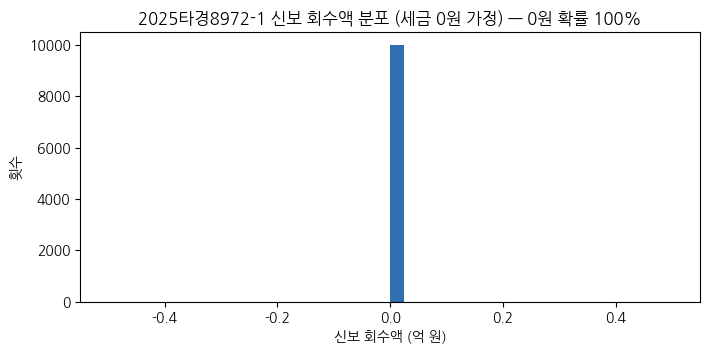

In [9]:
import matplotlib.pyplot as plt
!pip -q install koreanize-matplotlib
import koreanize_matplotlib

PICK = done["key"].iloc[0] if len(done) else None   # 보고 싶은 사건번호-물건번호로 바꾸세요 (예: "2025타경31425-1")
if PICK:
    tb = pd.DataFrame(tables); display(tb[tb.key == PICK])
    row = target[target.key == PICK].iloc[0]; pr = pred[pred.key == PICK].iloc[0]
    make_groups, info = build_case(row)
    r2 = np.random.default_rng(SEED)
    prices = info["감정가"] * sample_ratio(pr.p10, pr.p50, pr.p90, N_SIM, r2)
    paid, _ = waterfall(prices, make_groups(0))
    S = sum(paid.get(sid, np.zeros(N_SIM)) for sid in info["sinbo_ids"])
    plt.figure(figsize=(8, 3.5)); plt.hist(S / 1e8, bins=40, color="#2F6FB0")
    plt.title(f"{PICK} 신보 회수액 분포 (세금 0원 가정) — 0원 확률 {(S <= 0.5).mean():.0%}")
    plt.xlabel("신보 회수액 (억 원)"); plt.ylabel("횟수"); plt.show()